# Python technologies statistics

In [1]:
import datetime
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df_dou = pd.read_csv("../output/dou_vacancies.csv")
df_work_ua = pd.read_csv("../output/work_ua_vacancies.csv")

df = pd.concat([df_dou, df_work_ua], ignore_index=True)

In [3]:
df.head()

,company,name,posted_date,technologies
0,Qencode,"Python Engineer (Backend Automation, Video) — ...",2025-04-14,"Python,ORM,Docker,Kubernetes,RabbitMQ,TypeScri..."
1,Quod Financial,QA General (Python),2025-04-14,"Python,ORM,Jenkins,TypeScript,Git,DL,CV"
2,CostCare AI,"Tech lead, Python",2025-04-14,"Python,FastAPI,MongoDB,ORM,asyncio,TypeScript,..."
3,ProstoPay,Full Stack Developer (Python is in priority) д...,2025-03-27,"Python,PostgreSQL,MySQL,Docker,Kubernetes,Java..."
4,Niko Technologies,Agentic AI Specialist (Python),2025-04-10,"Python,ORM,TypeScript,ML,DL"


In [4]:
current_date = datetime.datetime.now().strftime("%Y-%m-%d")
figures_dir = "../output/figures"
os.makedirs(figures_dir, exist_ok=True)

In [6]:
df["technologies"] = df["technologies"].apply(lambda x: x.split(',') if isinstance(x, str) else x)

In [7]:
tech_counts = df["technologies"].explode().value_counts()

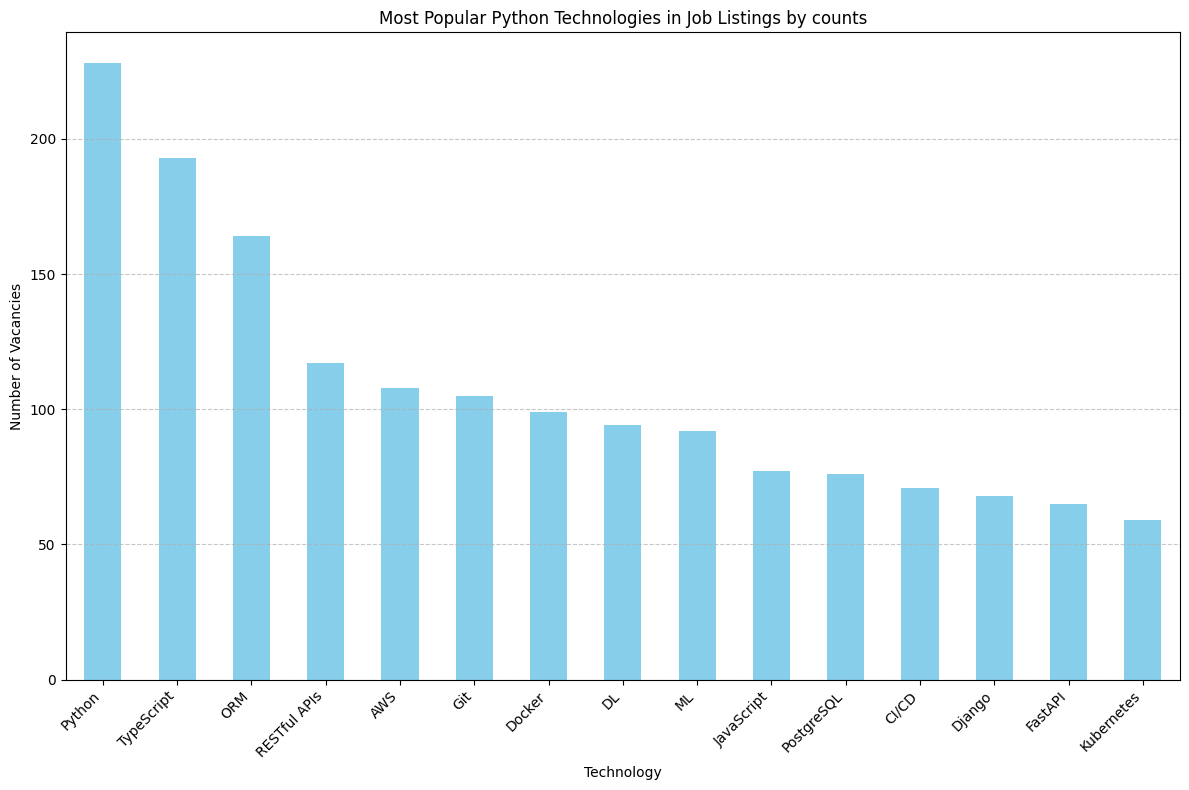

In [8]:
plt.figure(figsize=(12, 8))
tech_counts.head(15).plot(kind="bar", color="skyblue")
plt.title("Most Popular Python Technologies in Job Listings by counts")
plt.xlabel("Technology")
plt.ylabel("Number of Vacancies")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig(f"{figures_dir}/tech_counts_{current_date}.png")
plt.show()

In [9]:
total_vacancies = len(df)
tech_percentage = tech_counts / total_vacancies * 100

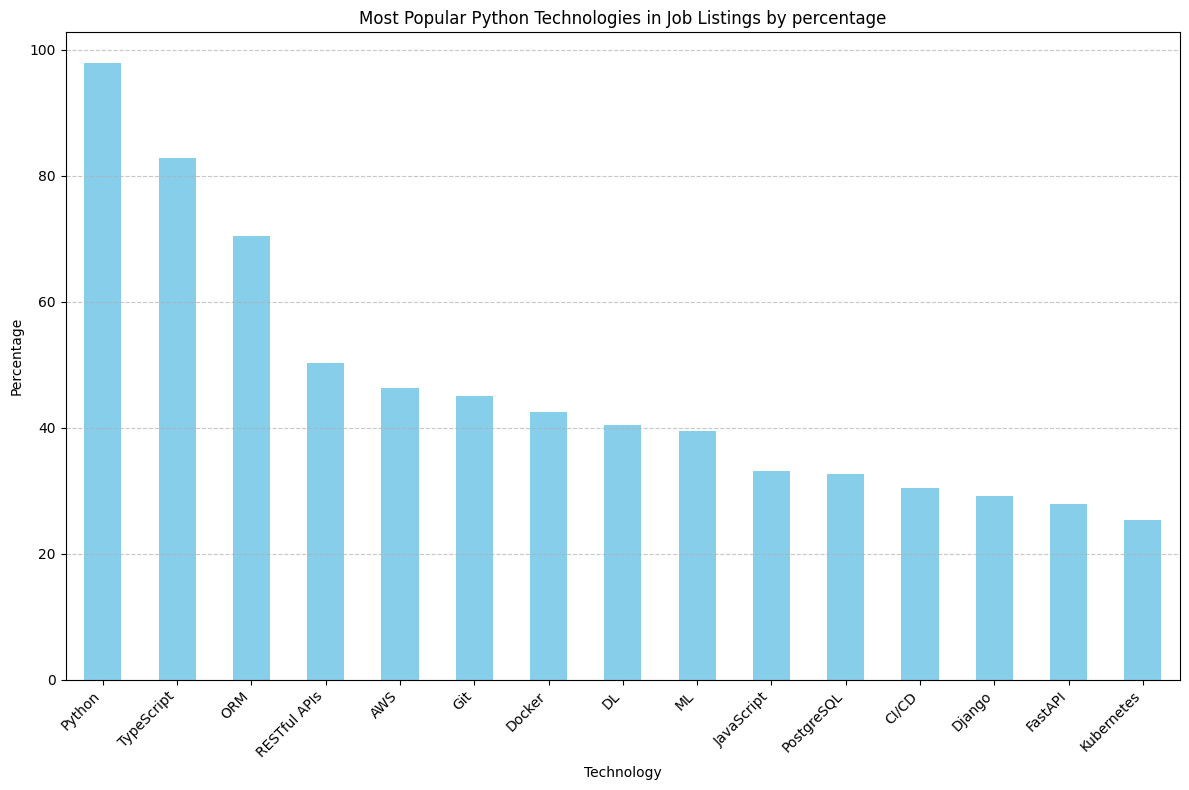

In [10]:
plt.figure(figsize=(12, 8))
tech_percentage.head(15).plot(kind="bar", color="skyblue")
plt.title("Most Popular Python Technologies in Job Listings by percentage")
plt.xlabel("Technology")
plt.ylabel("Percentage")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig(f"{figures_dir}/tech_percentage_{current_date}.png")
plt.show()